# 1. Import thư viện, đọc Train và Validation đã qua Processing E14


In [1]:
from pathlib import Path
import inspect
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# ========================================
# 1. CẤU HÌNH E14
# ========================================

EXPERIMENT_ID = "E14"
COMPARE_ID = "E13"

TARGET = "Attack_type"
RANDOM_STATE = 42
N_SPLITS = 3

# ========================================
# 2. TÌM THƯ MỤC GỐC SAMPLE_PROJECT
# ========================================

CURRENT = Path.cwd().resolve()

ROOT = next(
    (
        p for p in [CURRENT, *CURRENT.parents]
        if (p / "project").is_dir()
        and (p / "result").is_dir()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục sample_project. "
        "Hãy mở VS Code tại thư mục dự án."
    )

# ========================================
# 3. DỮ LIỆU CHUNG CỦA NHÓM
# ========================================

DATA_DIR = (
    ROOT / "result" / "preprocessing"
    / "E14_MLP_SignedLog_Alpha001_Processing" / "data"
)

TRAIN_PATH = DATA_DIR / "train.csv.gz"
VALID_PATH = DATA_DIR / "validation.csv.gz"

# ========================================
# 4. THƯ MỤC KẾT QUẢ E14
# ========================================

RESULT_DIR = (
    ROOT / "result"
    / "exps"
    / "E14_MLP_SignedLog_Alpha001"
)

# Chỉ tạo một thư mục, không có folder con
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# ========================================
# 5. KIỂM TRA VÀ ĐỌC DỮ LIỆU
# ========================================

if not TRAIN_PATH.is_file():
    raise FileNotFoundError(TRAIN_PATH)

if not VALID_PATH.is_file():
    raise FileNotFoundError(VALID_PATH)

train_df = pd.read_csv(TRAIN_PATH)
valid_df = pd.read_csv(VALID_PATH)

print("=== THỰC NGHIỆM E14 ===")
print("MLP + Signed-log + StandardScaler")
print("Hidden layers: (128, 64)")
print("Alpha: 0.01")

print("\n=== NGUỒN DỮ LIỆU ===")
print("Train:", TRAIN_PATH)
print("Validation:", VALID_PATH)

print("\n=== KÍCH THƯỚC ===")
print("Train:", train_df.shape)
print("Validation:", valid_df.shape)

print("\n=== THƯ MỤC KẾT QUẢ ===")
print(RESULT_DIR)

display(train_df.head(3))

=== THỰC NGHIỆM E14 ===
MLP + Signed-log + StandardScaler
Hidden layers: (128, 64)
Alpha: 0.01

=== NGUỒN DỮ LIỆU ===
Train: D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\preprocessing\E14_MLP_SignedLog_Alpha001_Processing\data\train.csv.gz
Validation: D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\preprocessing\E14_MLP_SignedLog_Alpha001_Processing\data\validation.csv.gz

=== KÍCH THƯỚC ===
Train: (82536, 83)
Validation: (17686, 83)

=== THƯ MỤC KẾT QUẢ ===
D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\exps\E14_MLP_SignedLog_Alpha001


,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,11.069416,10.747917,udp,-,0.000000,0.693147,0.000000,0.693147,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,NMAP_UDP_SCAN
1,9.913933,3.091042,tcp,-,0.000005,0.693147,0.693147,0.693147,0.0,12.204721,...,0.0,0.0,0.0,0.0,0.0,0.0,4.174387,0.0,4.174387,DOS_SYN_Hping
2,8.214736,3.091042,tcp,-,0.000005,0.693147,0.693147,0.693147,0.0,12.204721,...,0.0,0.0,0.0,0.0,0.0,0.0,4.174387,0.0,4.174387,DOS_SYN_Hping


# 2. Xây dựng Pipeline SignedLog + StandardScaler + MLP

In [2]:
# ========================================
# 1. TÁCH ĐẶC TRƯNG VÀ NHÃN
# ========================================

DROP_COLS = [
    TARGET,
    "Unnamed: 0",
    "group_id"
]

CATEGORICAL_FEATURES = [
    "proto",
    "service"
]

# Kiểm tra nhãn
if (
    TARGET not in train_df.columns
    or TARGET not in valid_df.columns
):
    raise ValueError(
        f"Thiếu cột nhãn {TARGET}"
    )

if (
    train_df[TARGET].isna().any()
    or valid_df[TARGET].isna().any()
):
    raise ValueError("Nhãn chứa giá trị thiếu")

# Tách Train
X = train_df.drop(
    columns=DROP_COLS,
    errors="ignore"
).copy()

y = train_df[TARGET].astype(str).copy()

# Tách Validation
X_valid = valid_df.drop(
    columns=DROP_COLS,
    errors="ignore"
).copy()

y_valid = valid_df[TARGET].astype(str).copy()

# Đồng bộ cột đặc trưng
if set(X.columns) != set(X_valid.columns):
    raise ValueError(
        "Train và Validation không có cùng đặc trưng"
    )

X_valid = X_valid[X.columns]

# ========================================
# 2. PHÂN LOẠI ĐẶC TRƯNG
# ========================================

missing_categories = [
    col for col in CATEGORICAL_FEATURES
    if col not in X.columns
]

if missing_categories:
    raise ValueError(
        f"Thiếu cột categorical: {missing_categories}"
    )

NUMERIC_FEATURES = X.select_dtypes(
    include=np.number
).columns.tolist()

unknown_features = sorted(
    set(X.columns)
    - set(NUMERIC_FEATURES)
    - set(CATEGORICAL_FEATURES)
)

if unknown_features:
    raise ValueError(
        f"Các cột chưa được xử lý: {unknown_features}"
    )

# ========================================
# 3. KIỂM TRA DỮ LIỆU
# ========================================

if X.isna().any().any() or X_valid.isna().any().any():
    raise ValueError(
        "Dữ liệu chung của nhóm còn giá trị NaN"
    )

if not np.isfinite(
    X[NUMERIC_FEATURES].to_numpy(dtype=float)
).all():
    raise ValueError(
        "Train có giá trị số vô hạn"
    )

if not np.isfinite(
    X_valid[NUMERIC_FEATURES].to_numpy(dtype=float)
).all():
    raise ValueError(
        "Validation có giá trị số vô hạn"
    )

# Danh sách nhãn
LABELS = sorted(y.unique().tolist())

if not set(y_valid.unique()).issubset(set(LABELS)):
    raise ValueError(
        "Validation có nhãn không tồn tại trong Train"
    )

if y.value_counts().min() < N_SPLITS:
    raise ValueError(
        "Mỗi lớp cần ít nhất 3 mẫu để chạy 3-fold CV"
    )

# ========================================
# 4. HÀM SIGNED-LOG
# ========================================

def signed_log(values):
    """
    Signed-log:
        sign(x) * log(1 + abs(x))
    """

    values = np.asarray(
        values,
        dtype=np.float64
    )

    return (
        np.sign(values)
        * np.log1p(np.abs(values))
    )

# ========================================
# 5. HÀM TẠO PIPELINE E14
# ========================================

def make_e14_pipeline():

    # Tương thích các phiên bản sklearn
    ohe_args = {
        "handle_unknown": "ignore"
    }

    if "sparse_output" in inspect.signature(
        OneHotEncoder
    ).parameters:
        ohe_args["sparse_output"] = False
    else:
        ohe_args["sparse"] = False

    # Signed-log đã được thực hiện trong Processing.
    # StandardScaler được fit riêng theo từng fold CV.
    numeric_pipeline = Pipeline([
        ("scaler", StandardScaler())
    ])

    # Tiền xử lý
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                numeric_pipeline,
                NUMERIC_FEATURES
            ),
            (
                "categorical",
                OneHotEncoder(**ohe_args),
                CATEGORICAL_FEATURES
            )
        ],
        remainder="drop",
        sparse_threshold=0
    )

    # MLP E14
    mlp = MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=0.01,
        learning_rate_init=0.001,
        batch_size=512,
        max_iter=60,
        n_iter_no_change=8,
        early_stopping=False,
        random_state=RANDOM_STATE,
        verbose=False
    )

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", mlp)
    ])

# ========================================
# 6. CÁC CHỈ SỐ ĐÁNH GIÁ
# ========================================

METRICS = [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "macro_precision",
    "macro_recall"
]


def evaluate(y_true, y_pred):

    return {
        "accuracy": accuracy_score(
            y_true, y_pred
        ),

        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="weighted",
            zero_division=0
        ),

        "macro_precision": precision_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),

        "macro_recall": recall_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        )
    }

# ========================================
# 7. KIỂM TRA PIPELINE
# ========================================

model_check = make_e14_pipeline()

print("=== THÔNG TIN E14 ===")
print("Train:", len(X))
print("Validation:", len(X_valid))
print("Số lớp:", len(LABELS))
print("Số đặc trưng số:", len(NUMERIC_FEATURES))
print("Categorical:", CATEGORICAL_FEATURES)

print("\n=== MÔ HÌNH MLP ===")
print(model_check.named_steps["model"])

assert model_check.named_steps["model"].alpha == 0.01

print("\n=== KIỂM TRA SIGNED-LOG ===")

sample_values = np.array(
    [-100, -10, -1, 0, 1, 10, 100],
    dtype=float
)

display(pd.DataFrame({
    "original": sample_values,
    "signed_log": signed_log(sample_values)
}))

print("\n=== PHÂN BỐ NHÃN TRAIN ===")
display(y.value_counts())

=== THÔNG TIN E14 ===
Train: 82536
Validation: 17686
Số lớp: 12
Số đặc trưng số: 80
Categorical: ['proto', 'service']

=== MÔ HÌNH MLP ===
MLPClassifier(alpha=0.01, batch_size=512, hidden_layer_sizes=(128, 64),
              max_iter=60, n_iter_no_change=8, random_state=42)

=== KIỂM TRA SIGNED-LOG ===


,original,signed_log
0,-100.0,-4.615121
1,-10.0,-2.397895
2,-1.0,-0.693147
3,0.0,0.000000
4,1.0,0.693147
5,10.0,2.397895
6,100.0,4.615121



=== PHÂN BỐ NHÃN TRAIN ===


Attack_type
DOS_SYN_Hping                 63062
Thing_Speak                    5355
ARP_poisioning                 5334
MQTT_Publish                   2899
NMAP_UDP_SCAN                  1807
NMAP_XMAS_TREE_SCAN            1407
NMAP_OS_DETECTION              1400
NMAP_TCP_scan                   701
DDOS_Slowloris                  373
Wipro_bulb                      153
Metasploit_Brute_Force_SSH       25
NMAP_FIN_SCAN                    20
Name: count, dtype: int64

# 3. Huấn luyện 3-ford Cross-Validation

In [3]:
# ========================================
# 1. KHỞI TẠO 3-FOLD CV
# ========================================

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

fold_rows = []
per_class_rows = []
loss_curves = {}

# ========================================
# 2. HUẤN LUYỆN TỪNG FOLD
# ========================================

for fold, (fit_idx, cv_idx) in enumerate(
    cv.split(X, y),
    start=1
):

    print("\n" + "=" * 55)
    print(f"E14 - FOLD {fold}/{N_SPLITS}")
    print("=" * 55)

    # Train của fold
    X_fit = X.iloc[fit_idx]
    y_fit = y.iloc[fit_idx]

    # Kiểm định của fold
    X_cv = X.iloc[cv_idx]
    y_cv = y.iloc[cv_idx]

    # Tạo Pipeline mới
    fold_pipeline = make_e14_pipeline()

    start_time = time.perf_counter()

    # Huấn luyện
    fold_pipeline.fit(X_fit, y_fit)

    elapsed = time.perf_counter() - start_time

    # Dự đoán
    pred_cv = fold_pipeline.predict(X_cv)
    pred_train = fold_pipeline.predict(X_fit)

    # Tính chỉ số
    cv_scores = evaluate(y_cv, pred_cv)
    train_scores = evaluate(y_fit, pred_train)

    trained_mlp = fold_pipeline.named_steps["model"]

    # Lưu Training Loss
    loss_curves[fold] = list(
        trained_mlp.loss_curve_
    )

    # Lưu kết quả từng fold
    fold_rows.append({
        "fold": fold,
        "n_train": len(X_fit),
        "n_cv": len(X_cv),
        "epochs": int(trained_mlp.n_iter_),
        "training_time_sec": float(elapsed),
        "final_train_loss": float(trained_mlp.loss_),

        **cv_scores,

        **{
            f"train_{m}": train_scores[m]
            for m in METRICS
        }
    })

    # Đánh giá theo từng lớp
    p, r, f, support = (
        precision_recall_fscore_support(
            y_cv,
            pred_cv,
            labels=LABELS,
            zero_division=0
        )
    )

    for label, precision, recall, f1_value, n in zip(
        LABELS,
        p,
        r,
        f,
        support
    ):

        per_class_rows.append({
            "fold": fold,
            "class": label,
            "precision": float(precision),
            "recall": float(recall),
            "f1": float(f1_value),
            "support": int(n)
        })

    print("Số mẫu Train:", len(X_fit))
    print("Số mẫu CV:", len(X_cv))
    print("Số epoch:", trained_mlp.n_iter_)
    print(f"Thời gian: {elapsed:.2f} giây")

    print("\n=== 5 CHỈ SỐ ===")

    for metric in METRICS:
        print(
            f"{metric:18s}: {cv_scores[metric]:.6f}"
        )

# ========================================
# 3. TỔNG HỢP KẾT QUẢ
# ========================================

cv_results = pd.DataFrame(fold_rows)
cv_per_class = pd.DataFrame(per_class_rows)

cv_summary = pd.DataFrame({
    "metric": METRICS,

    "mean": [
        float(cv_results[m].mean())
        for m in METRICS
    ],

    "std": [
        float(cv_results[m].std(ddof=1))
        for m in METRICS
    ]
})

cv_per_class_summary = (
    cv_per_class
    .groupby("class", as_index=False)
    .agg(
        precision_mean=("precision", "mean"),
        recall_mean=("recall", "mean"),
        f1_mean=("f1", "mean"),
        support_total=("support", "sum")
    )
    .sort_values("f1_mean")
)

print("\n=== KẾT QUẢ 3 FOLD ===")

display(
    cv_results[
        [
            "fold",
            *METRICS,
            "epochs",
            "training_time_sec"
        ]
    ].round(6)
)

print("\n=== TRUNG BÌNH 3 FOLD ===")
display(cv_summary.round(6))

print("\n=== 5 LỚP CÓ F1 THẤP NHẤT ===")
display(
    cv_per_class_summary.head(5).round(6)
)

# ========================================
# 4. LƯU CSV
# ========================================

cv_results.to_csv(
    RESULT_DIR / "E14_cv_folds.csv",
    index=False,
    encoding="utf-8-sig"
)

cv_summary.to_csv(
    RESULT_DIR / "E14_cv_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

cv_per_class.to_csv(
    RESULT_DIR / "E14_cv_per_class.csv",
    index=False,
    encoding="utf-8-sig"
)

cv_per_class_summary.to_csv(
    RESULT_DIR / "E14_cv_per_class_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu kết quả CV vào:")
print(RESULT_DIR)


E14 - FOLD 1/3


Số mẫu Train: 55024
Số mẫu CV: 27512
Số epoch: 57
Thời gian: 17.99 giây

=== 5 CHỈ SỐ ===
accuracy          : 0.996256
macro_f1          : 0.952183
weighted_f1       : 0.996199
macro_precision   : 0.988027
macro_recall      : 0.925242

E14 - FOLD 2/3


Số mẫu Train: 55024
Số mẫu CV: 27512
Số epoch: 50
Thời gian: 15.37 giây

=== 5 CHỈ SỐ ===
accuracy          : 0.996002
macro_f1          : 0.934195
weighted_f1       : 0.995943
macro_precision   : 0.960030
macro_recall      : 0.915819

E14 - FOLD 3/3


D:\Programdata2026\Anaconda3\envs\sgu_ml\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


Số mẫu Train: 55024
Số mẫu CV: 27512
Số epoch: 60
Thời gian: 18.62 giây

=== 5 CHỈ SỐ ===
accuracy          : 0.995965
macro_f1          : 0.963417
weighted_f1       : 0.995938
macro_precision   : 0.967818
macro_recall      : 0.960712

=== KẾT QUẢ 3 FOLD ===


,fold,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,epochs,training_time_sec
0,1,0.996256,0.952183,0.996199,0.988027,0.925242,57,17.991319
1,2,0.996002,0.934195,0.995943,0.960030,0.915819,50,15.370170
2,3,0.995965,0.963417,0.995938,0.967818,0.960712,60,18.619447



=== TRUNG BÌNH 3 FOLD ===


,metric,mean,std
0,accuracy,0.996074,0.000158
1,macro_f1,0.949932,0.014740
2,weighted_f1,0.996027,0.000150
3,macro_precision,0.971958,0.014450
4,macro_recall,0.933924,0.023673



=== 5 LỚP CÓ F1 THẤP NHẤT ===


,class,precision_mean,recall_mean,f1_mean,support_total
4,Metasploit_Brute_Force_SSH,0.859259,0.754630,0.793363,25
5,NMAP_FIN_SCAN,0.952381,0.841270,0.885714,20
1,DDOS_Slowloris,0.977686,0.823097,0.893741,373
11,Wipro_bulb,0.955660,0.843137,0.894917,153
8,NMAP_UDP_SCAN,0.962191,0.985611,0.973758,1807



Đã lưu kết quả CV vào:
D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\exps\E14_MLP_SignedLog_Alpha001


# 4. huấn luyện full train và đánh giá Validation

In [4]:
# ========================================
# 1. HUẤN LUYỆN FULL TRAIN
# ========================================

final_model = make_e14_pipeline()

start_time = time.perf_counter()

final_model.fit(X, y)

full_train_time = (
    time.perf_counter() - start_time
)

# ========================================
# 2. DỰ ĐOÁN
# ========================================

pred_train = final_model.predict(X)
pred_valid = final_model.predict(X_valid)

train_scores = evaluate(y, pred_train)
valid_scores = evaluate(y_valid, pred_valid)

final_mlp = final_model.named_steps["model"]

print("=== E14 - FULL TRAIN ===")
print("Số mẫu Train:", len(X))
print("Alpha:", final_mlp.alpha)
print("Số epoch:", final_mlp.n_iter_)

print(f"Thời gian: {full_train_time:.2f} giây")
print(f"Training Loss: {final_mlp.loss_:.6f}")

# ========================================
# 3. BẢNG TRAIN / VALIDATION
# ========================================

validation_metrics = pd.DataFrame({
    "metric": METRICS,

    "train": [
        train_scores[m]
        for m in METRICS
    ],

    "validation": [
        valid_scores[m]
        for m in METRICS
    ]
})

validation_metrics["train_valid_gap"] = (
    validation_metrics["train"]
    - validation_metrics["validation"]
)

print("\n=== TRAIN / VALIDATION ===")
display(validation_metrics.round(6))

# ========================================
# 4. KẾT QUẢ THEO TỪNG LỚP
# ========================================

p, r, f, support = (
    precision_recall_fscore_support(
        y_valid,
        pred_valid,
        labels=LABELS,
        zero_division=0
    )
)

validation_per_class = pd.DataFrame({
    "class": LABELS,
    "precision": p,
    "recall": r,
    "f1": f,
    "support": support
})

print("\n=== KẾT QUẢ TỪNG LỚP ===")

display(
    validation_per_class
    .sort_values("f1")
    .round(6)
)

# ========================================
# 5. CONFUSION MATRIX
# ========================================

cm = confusion_matrix(
    y_valid,
    pred_valid,
    labels=LABELS
)

cm_df = pd.DataFrame(
    cm,
    index=LABELS,
    columns=LABELS
)

# ========================================
# 6. TỔNG HỢP CV / VALIDATION
# ========================================

cv_vs_validation = (
    cv_summary[
        ["metric", "mean", "std"]
    ]
    .merge(
        validation_metrics[
            ["metric", "validation"]
        ],
        on="metric"
    )
)

cv_vs_validation["validation_minus_cv_mean"] = (
    cv_vs_validation["validation"]
    - cv_vs_validation["mean"]
)

print("\n=== CV / VALIDATION E14 ===")
display(cv_vs_validation.round(6))

# ========================================
# 7. LƯU KẾT QUẢ
# ========================================

validation_metrics.to_csv(
    RESULT_DIR / "E14_validation_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

validation_per_class.to_csv(
    RESULT_DIR / "E14_validation_per_class.csv",
    index=False,
    encoding="utf-8-sig"
)

cm_df.to_csv(
    RESULT_DIR / "E14_validation_confusion_matrix.csv",
    encoding="utf-8-sig"
)

cv_vs_validation.to_csv(
    RESULT_DIR / "E14_cv_vs_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu kết quả Validation.")

D:\Programdata2026\Anaconda3\envs\sgu_ml\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


=== E14 - FULL TRAIN ===
Số mẫu Train: 82536
Alpha: 0.01
Số epoch: 60
Thời gian: 29.29 giây
Training Loss: 0.009243

=== TRAIN / VALIDATION ===


,metric,train,validation,train_valid_gap
0,accuracy,0.997262,0.996494,0.000767
1,macro_f1,0.966840,0.960707,0.006133
2,weighted_f1,0.997226,0.996470,0.000756
3,macro_precision,0.990193,0.974570,0.015622
4,macro_recall,0.948548,0.952317,-0.003769



=== KẾT QUẢ TỪNG LỚP ===


,class,precision,recall,f1,support
5,NMAP_FIN_SCAN,1.000000,0.750000,0.857143,4
11,Wipro_bulb,0.935484,0.878788,0.906250,33
4,Metasploit_Brute_Force_SSH,0.833333,1.000000,0.909091,5
1,DDOS_Slowloris,1.000000,0.850000,0.918919,80
8,NMAP_UDP_SCAN,0.964646,0.987080,0.975734,387
0,ARP_poisioning,0.968511,0.995626,0.981881,1143
10,Thing_Speak,0.992870,0.971229,0.981930,1147
9,NMAP_XMAS_TREE_SCAN,1.000000,0.996689,0.998342,302
3,MQTT_Publish,1.000000,0.998390,0.999194,621
7,NMAP_TCP_scan,1.000000,1.000000,1.000000,151



=== CV / VALIDATION E14 ===


,metric,mean,std,validation,validation_minus_cv_mean
0,accuracy,0.996074,0.000158,0.996494,0.000420
1,macro_f1,0.949932,0.014740,0.960707,0.010775
2,weighted_f1,0.996027,0.000150,0.996470,0.000443
3,macro_precision,0.971958,0.014450,0.974570,0.002612
4,macro_recall,0.933924,0.023673,0.952317,0.018392



Đã lưu kết quả Validation.


# 5. Vẽ biểu đồ kết quả

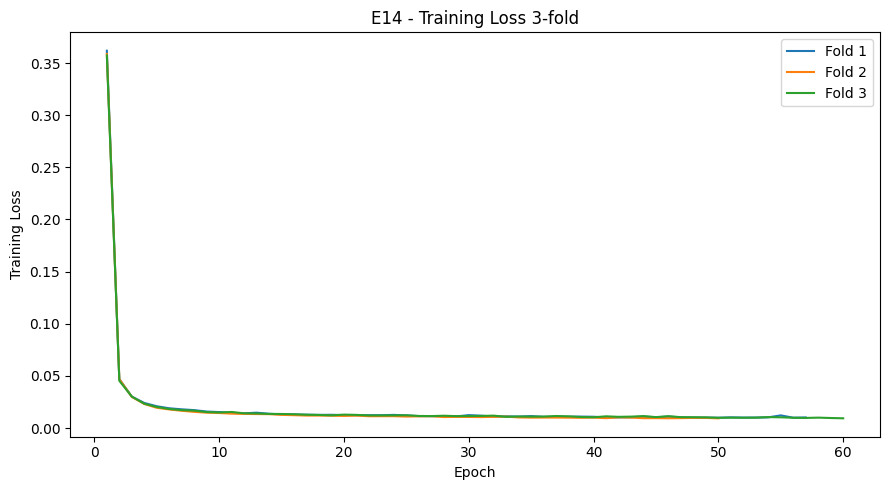

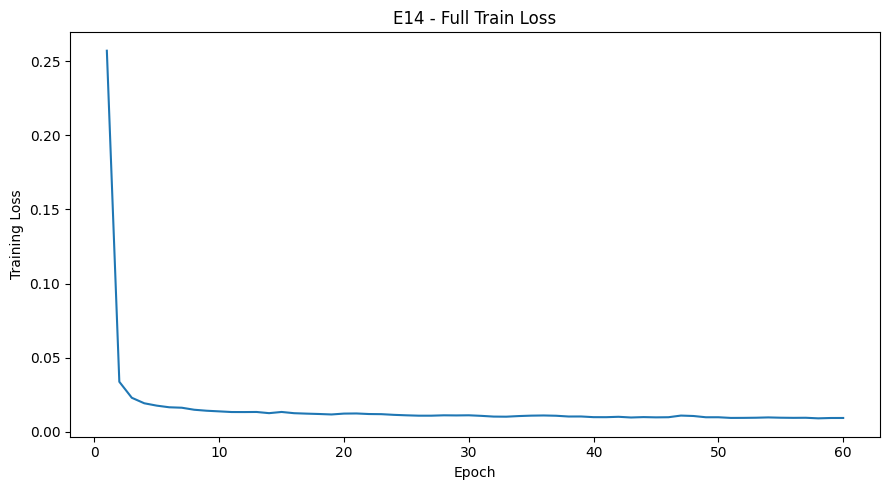

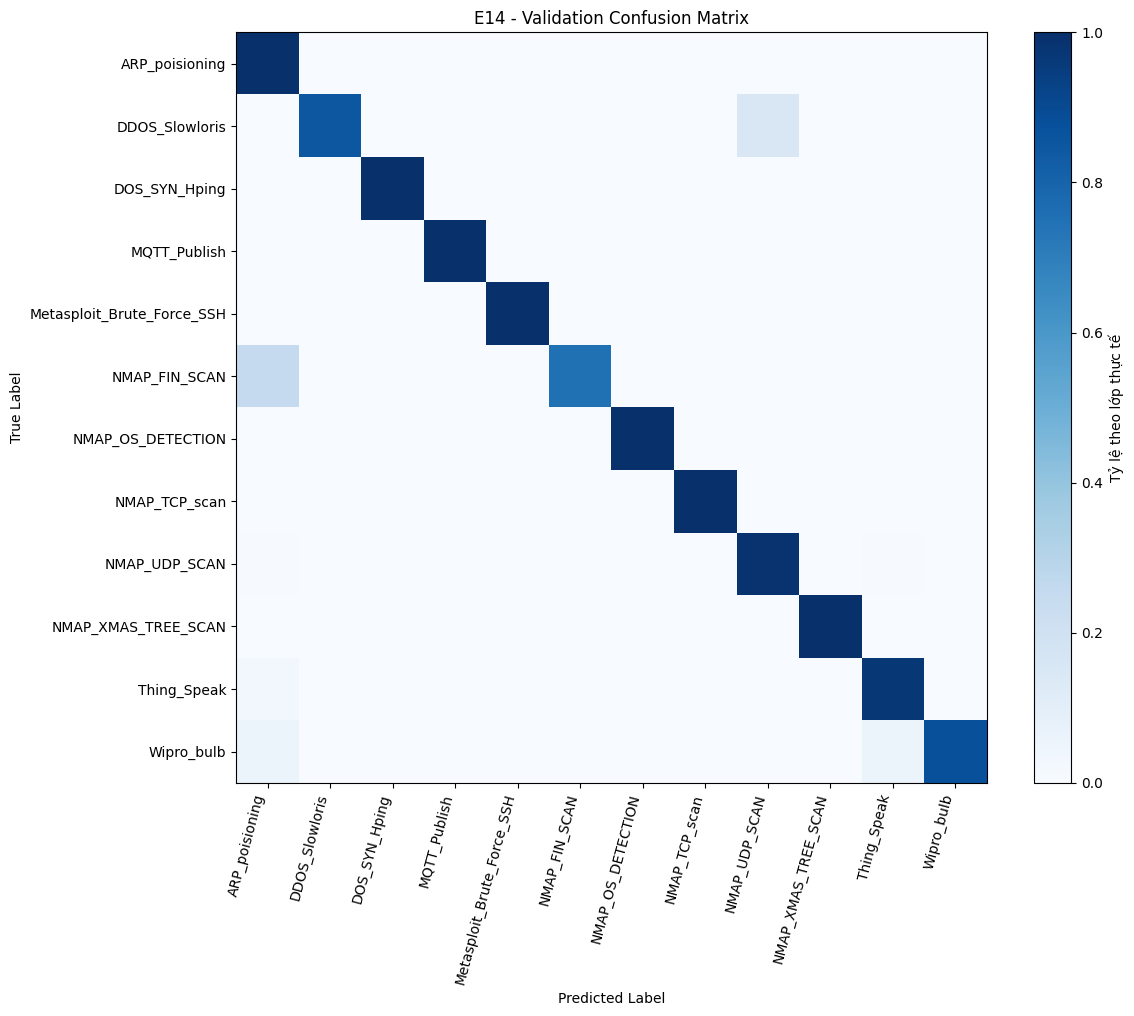

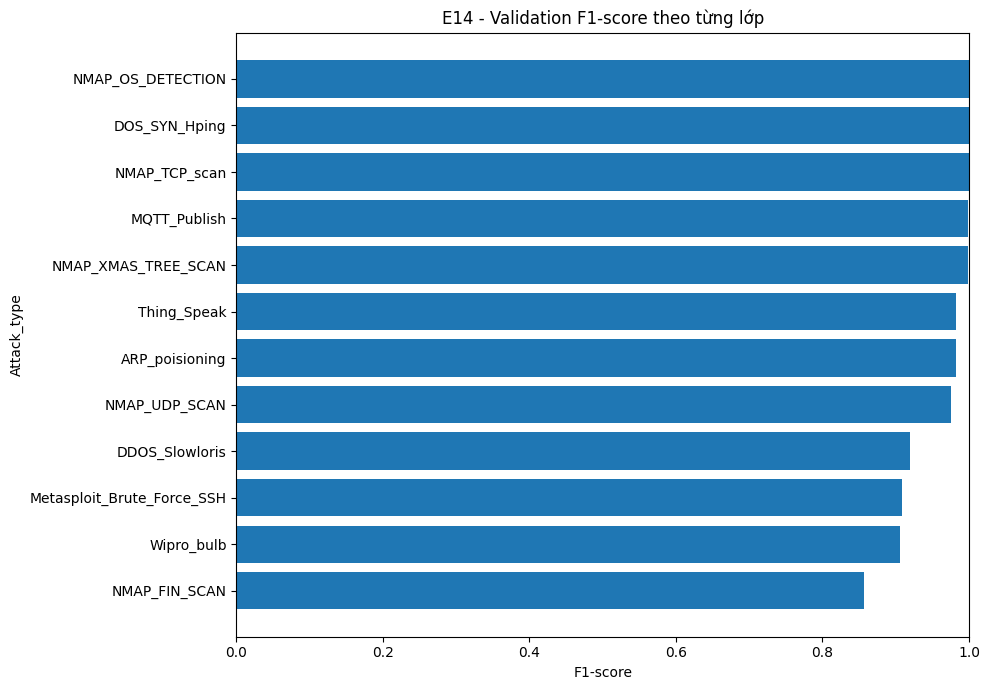

=== ĐÃ LƯU 4 HÌNH PNG ===
D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\exps\E14_MLP_SignedLog_Alpha001


In [5]:
# ========================================
# 5.1. TRAINING LOSS 3 FOLD
# ========================================

fig, ax = plt.subplots(figsize=(9, 5))

for fold, losses in loss_curves.items():

    ax.plot(
        range(1, len(losses) + 1),
        losses,
        label=f"Fold {fold}"
    )

ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss")
ax.set_title("E14 - Training Loss 3-fold")

ax.legend()
fig.tight_layout()

fig.savefig(
    RESULT_DIR / "E14_3fold_training_loss.png",
    dpi=160
)

plt.show()


# ========================================
# 5.2. TRAINING LOSS FULL TRAIN
# ========================================

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    range(1, len(final_mlp.loss_curve_) + 1),
    final_mlp.loss_curve_
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss")
ax.set_title("E14 - Full Train Loss")

fig.tight_layout()

fig.savefig(
    RESULT_DIR / "E14_full_train_loss.png",
    dpi=160
)

plt.show()


# ========================================
# 5.3. CONFUSION MATRIX VALIDATION
# ========================================

row_totals = cm.sum(
    axis=1,
    keepdims=True
)

cm_normalized = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    cm_normalized,
    cmap="Blues",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(LABELS)))
ax.set_yticks(range(len(LABELS)))

ax.set_xticklabels(
    LABELS,
    rotation=75,
    ha="right"
)

ax.set_yticklabels(LABELS)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

ax.set_title(
    "E14 - Validation Confusion Matrix"
)

fig.colorbar(
    im,
    ax=ax,
    label="Tỷ lệ theo lớp thực tế"
)

fig.tight_layout()

fig.savefig(
    RESULT_DIR / "E14_validation_confusion_matrix.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# ========================================
# 5.4. F1-SCORE THEO TỪNG LỚP
# ========================================

f1_plot = (
    validation_per_class
    .sort_values("f1")
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    f1_plot["class"],
    f1_plot["f1"]
)

ax.set_xlim(0, 1)

ax.set_xlabel("F1-score")
ax.set_ylabel("Attack_type")

ax.set_title(
    "E14 - Validation F1-score theo từng lớp"
)

fig.tight_layout()

fig.savefig(
    RESULT_DIR / "E14_validation_f1_per_class.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("=== ĐÃ LƯU 4 HÌNH PNG ===")
print(RESULT_DIR)

# 6. Xuất file Excel và lưu cấu hình

In [6]:
from openpyxl import Workbook

from openpyxl.styles import (
    Font,
    Alignment,
    PatternFill,
    Border,
    Side
)

from openpyxl.utils import get_column_letter

# ========================================
# 1. TẠO WORKBOOK
# ========================================

excel_path = (
    RESULT_DIR / "E14_MLP_3Fold_KetQua.xlsx"
)

wb = Workbook()
ws = wb.active

ws.title = "E14 Alpha 0.01"
ws.sheet_view.showGridLines = False

# ========================================
# 2. TIÊU ĐỀ
# ========================================

ws.merge_cells("A1:Z1")

ws["A1"] = (
    "MÔ HÌNH: MLP - E14 "
    "SIGNED-LOG + STANDARDSCALER + ALPHA 0.01"
)

# ========================================
# 3. NHÓM CỘT
# ========================================

groups = {
    "A2:D2": "Các lượt chạy 3 cross validation",
    "E2:I2": "Lượt 1",
    "J2:N2": "Lượt 2",
    "O2:S2": "Lượt 3",
    "T2:X2": "Valid",
    "Y2:Z2": "Nhận xét"
}

for cell_range, title in groups.items():

    ws.merge_cells(cell_range)

    first_cell = cell_range.split(":")[0]

    ws[first_cell] = title

# ========================================
# 4. TÊN CỘT
# ========================================

headers = (
    [
        "MÃ",
        "MÃ SO SÁNH",
        "Xử lý dữ liệu",
        "Thông số model"
    ]
    + METRICS * 4
    + [
        "Điểm yếu",
        "Đã khắc phục"
    ]
)

for col, header in enumerate(
    headers,
    start=1
):

    ws.cell(
        row=3,
        column=col,
        value=header
    )

# ========================================
# 5. THÔNG TIN E14
# ========================================

ws["A4"] = "E14"
ws["B4"] = "E13"

ws["C4"] = (
    "Signed-log trước StandardScaler "
    "trên nhánh numeric; "
    "OneHotEncoder cho proto và service."
)

ws["D4"] = (
    "MLP (128,64), ReLU, Adam; "
    "alpha=0.01, "
    "learning_rate_init=0.001, "
    "batch_size=512, "
    "max_iter=60, "
    "n_iter_no_change=8, "
    "early_stopping=False, "
    "random_state=42"
)

# ========================================
# 6. GHI KẾT QUẢ 3 FOLD
# ========================================

scores_by_fold = cv_results.set_index("fold")

for fold in [1, 2, 3]:

    first_col = 5 + (fold - 1) * 5

    for idx, metric in enumerate(METRICS):

        score = float(
            scores_by_fold.loc[fold, metric]
        )

        cell = ws.cell(
            row=4,
            column=first_col + idx,
            value=score
        )

        cell.number_format = "0.000000"

# ========================================
# 7. GHI KẾT QUẢ VALIDATION
# ========================================

for idx, metric in enumerate(METRICS):

    score = float(valid_scores[metric])

    cell = ws.cell(
        row=4,
        column=20 + idx,
        value=score
    )

    cell.number_format = "0.000000"

# ========================================
# 8. NHẬN XÉT
# ========================================

ws["Y4"] = (
    "Chưa so sánh với E13; "
    "cần xem xét F1/Recall các lớp."
)

ws["Z4"] = (
    "Đã thử tăng alpha lên 0.01; "
    "chưa kết luận hiệu quả cải tiến."
)

# ========================================
# 9. ĐỊNH DẠNG EXCEL
# ========================================

ws["A1"].font = Font(
    name="Calibri",
    size=14,
    bold=True,
    color="16324F"
)

ws["A1"].alignment = Alignment(
    horizontal="center",
    vertical="center"
)

ws.row_dimensions[1].height = 32
ws.row_dimensions[2].height = 26
ws.row_dimensions[3].height = 38
ws.row_dimensions[4].height = 85

# Định dạng tiêu đề
for row_number, fill_color in [
    (2, "DCEAF7"),
    (3, "EAF1F8")
]:

    for row in ws.iter_rows(
        min_row=row_number,
        max_row=row_number,
        min_col=1,
        max_col=26
    ):

        for cell in row:

            cell.fill = PatternFill(
                "solid",
                fgColor=fill_color
            )

            cell.font = Font(
                name="Calibri",
                size=10,
                bold=True,
                color="17324D"
            )

            cell.alignment = Alignment(
                horizontal="center",
                vertical="center",
                wrap_text=True
            )

# Độ rộng cột
width_by_column = {
    "A": 20,
    "B": 17,
    "C": 41,
    "D": 56,
    "Y": 40,
    "Z": 42
}

for col, width in width_by_column.items():
    ws.column_dimensions[col].width = width

for col in range(5, 25):

    letter = get_column_letter(col)

    ws.column_dimensions[letter].width = 17

# Viền và căn chỉnh
thin = Side(
    style="thin",
    color="C5D1DD"
)

for row in ws.iter_rows(
    min_row=3,
    max_row=4,
    min_col=1,
    max_col=26
):

    for cell in row:

        cell.border = Border(
            left=thin,
            right=thin,
            top=thin,
            bottom=thin
        )

        if cell.row == 4:

            cell.alignment = Alignment(
                horizontal=(
                    "center"
                    if 5 <= cell.column <= 24
                    else "left"
                ),
                vertical="center",
                wrap_text=True
            )

ws.freeze_panes = "E4"

# ========================================
# 10. LƯU EXCEL
# ========================================

wb.save(excel_path)

print("=== ĐÃ XUẤT EXCEL E14 ===")
print(excel_path)

# ========================================
# 11. LƯU CẤU HÌNH
# ========================================

config = {
    "experiment": "E14",
    "compare_id": "E13",
    "model": "MLPClassifier",

    "numeric_transform": "Signed-log (E14 Processing)",
    "data_source": "result/preprocessing/E14_MLP_SignedLog_Alpha001_Processing/data",
    "preprocessing_notebook": "E14_MLP_SignedLog_Alpha001_Processing.ipynb",
    "alpha": 0.01,
    "numeric_scaler": "StandardScaler",
    "categorical_encoder": "OneHotEncoder",

    "hidden_layer_sizes": [128, 64],
    "activation": "relu",
    "solver": "adam",

    "alpha": 0.01,
    "learning_rate_init": 0.001,
    "batch_size": 512,

    "max_iter": 60,
    "n_iter_no_change": 8,
    "early_stopping": False,

    "random_state": RANDOM_STATE,
    "cv_folds": N_SPLITS,

    "train_samples": int(len(X)),
    "validation_samples": int(len(X_valid)),

    "classes": LABELS,
    "test_used": False,
    "comparison_completed": False
}

with open(
    RESULT_DIR / "E14_config.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        config,
        f,
        indent=2,
        ensure_ascii=False
    )

print("Đã lưu cấu hình E14.")

=== ĐÃ XUẤT EXCEL E14 ===
D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\exps\E14_MLP_SignedLog_Alpha001\E14_MLP_3Fold_KetQua.xlsx
Đã lưu cấu hình E14.
